# COMP2200/COMP6200 Assignment 1

Due date: 11:55pm on Sunday April 6th 2025

(Note that daylight savings ends earlier on that day. Remember to move your clock backward by an hour.)

## Scenario

You are working as a data scientist in a venture capital investment firm. You have been given some
data about a potential company to invest in. You will create some models to predict what the 
potential company will be like in 12 months' time.


## About this assignment

This assessment focuses on fundamental statistical analysis, which
will apply linear and logistic regression techniques on one or more
data sets.

The relevant ULO (Unit Learning Outcomes) are:

- Identify the appropriate Data Science analysis for a problem and
  apply that method to the problem.

- Interpret Data Science analyses and summarise and identify the most
  important aspects of a Data Science analysis.

- Present the results of their Data Science analyses both verbally and
  in written form.
  
Total: 15 marks
  

## Submission

Use https://classroom.github.com/a/BdRkY5OH to create a new empty
repository.

Complete this notebook and add it to a new GitHub repository.

Submit this repository via Github Classroom.

Add the video that you create (in the last step) to your GitHub repository.

You don't need to submit your CSV data file, but we won't penalise you
if you do.

## Use of Generative AI

Feel free to use Gen-AI tools (ChatGPT, Anthropic Claude, DeepSeek,
Llama, etc.) to assist you in writing the code. That's what everyone
in industry does nowadays. There are some suggested prompts at the bottom
of this notebook.

Remember that you may be called on to explain what your code does and
how it works, so if you have some code generated for you that you
don't fully understand, spend some time with your Gen-AI tool asking
for clarification until you are confident. Having a personal tutor
guide you is one of the newest and fastest ways to learn to program in
Python, so make the most of the opportunity. 

To help you remember what your code does, you can add comments to your
code either by creating another markdown cell, or by using "#" at the
beginning of a line in a code cell.

Don't use Gen-AI tools for writing reflections and observations. You
will find many cells in this notebook where you need to enter markdown text.
They appear like this:

**Your answer here. Replace the text in this markdown cell. Remember not to use Gen-AI here.**

You don't want to use Gen-AI in these cells for two reasons:

- Thinking and reflecting is how you will get most of the benefit of doing this assignment.

- It will produce meaningless and bland statements (that will be obviously meaningless and bland)
  and you will get bad marks.
  

## Marking Criteria

For a code cell, any working correct answer will earn full marks. For
non-working code, or code that performs a different task, if it seems
like you were on the right track, the marker may issue partial marks.

For code cells that create visualisations, a correct answer is one that
creates a meaningful and useful visualisation of the data.

For a text (markdown) cell, word counts are only a guide: this is how
many words we think it will take to give a good answer. If you need to
use more words, or can express your answer in less words, go ahead: a
good answer will still receive full marks.

Answers given as dot points in a markdown cell are acceptable;
likewise full sentences in paragraphs are acceptable.

## Resources

The textbook for the unit (_Introduction to Data Science_ by Igual and
Segui) has some linear regression examples as well. You might find
Section 6.2.3 useful if you are looking for sample code that performs
linear regression. Section 6.3.1 has an example of logistic
regression.


## Data

You will find a large zip file called `2025-S1-COMP2200-6200-assignment1.zip` on iLearn.  When you expand it
out, you will see many files, including one that begins with your
student number. e.g `1235345 Brown-Miller Group.csv`

Copy it into the same directory as you copied this Jupyter notebook.

### Create a GitHub repo within Github Classroom (0.1 marks)

- Yes, we'll give you 0.1 marks just for getting this far.

### Import any libraries you need (0.1 marks)



In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, HuberRegressor, LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler




If you are doing something exotic --- e.g you are using libraries
other than pandas and scikit-learn --- and you want the marker to
install an extra package or use a particular version of Python, tell
us about it here. Most students will leave this blank.



No extra packages are required. The notebook uses pandas, numpy, matplotlib, seaborn, and scikit-learn.




### Unzip and Load the Data (0.1 marks)

- Load the data into a DataFrame using `pd.read_csv()` into a variable called `df`.



In [2]:
df = pd.read_csv('company_data.csv')



### Inspect the Data (0.2 marks)

- List the column names using `df.columns`.



In [3]:
df.columns

Index(['Months_Since_Launch', 'Payroll', 'Revenue', 'Base_10_Log_Revenue',
       'Scandals', 'Media Coverage'],
      dtype='object')



- Explore the data in those columns. Briefly describe each column in one sentence.



In [4]:
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Months_Since_Launch  24 non-null     int64  
 1   Payroll              24 non-null     float64
 2   Revenue              24 non-null     float64
 3   Base_10_Log_Revenue  24 non-null     float64
 4   Scandals             24 non-null     int64  
 5   Media Coverage       24 non-null     object 
dtypes: float64(3), int64(2), object(1)
memory usage: 1.2+ KB


,Months_Since_Launch,Payroll,Revenue,Base_10_Log_Revenue,Scandals,Media Coverage
0,1,1483215.58,10943.00,4.0391,0,Positive
1,2,1551277.11,23566.44,4.3723,0,Positive
2,3,1621637.52,28662.87,4.4573,0,Positive
3,4,1729773.95,32194.23,4.5078,0,Positive
4,5,1764506.83,33231.02,4.5215,0,Positive





Suggested word count: ~100 words



The file has 24 months and six columns, with no missing values. Months_Since_Launch is the month number, from 1 to 24. Payroll is the wage bill in dollars; it trends up, with a sharp spike in month 11. Revenue is monthly revenue in dollars and rises over the two years, faster near the end. Base_10_Log_Revenue is the base-10 log of Revenue, so a step of 1 is a tenfold change in revenue. Scandals is 0 in 23 months and 1 only in month 14. Media Coverage is Positive in months 1 to 10 and Negative in months 11 to 24.




### Visualise Payroll Over Time (1 mark)

- Create a line plot clearly showing payroll over months since launch.



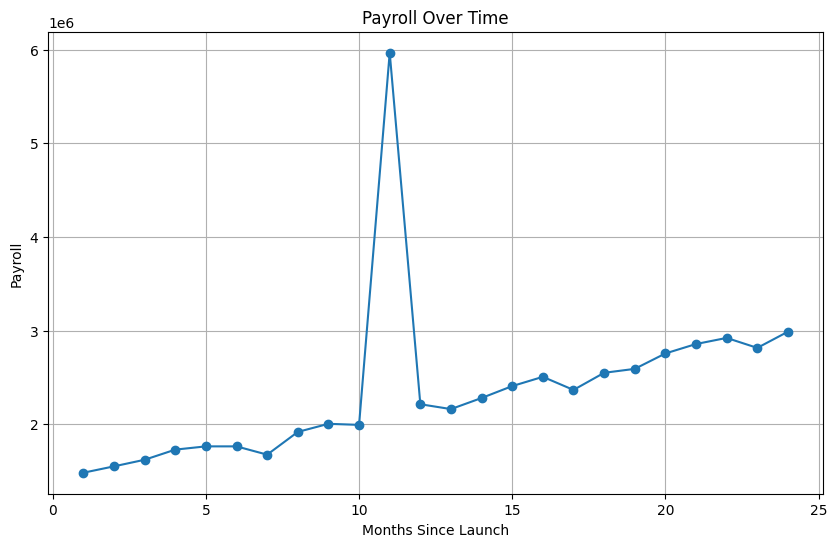

In [5]:
plt.figure(figsize=(10, 6))
plt.plot(df['Months_Since_Launch'], df['Payroll'], marker='o', linestyle='-')
plt.title('Payroll Over Time')
plt.xlabel('Months Since Launch')
plt.ylabel('Payroll')
plt.grid(True)
plt.show()



- Identify and briefly discuss any visible outliers.



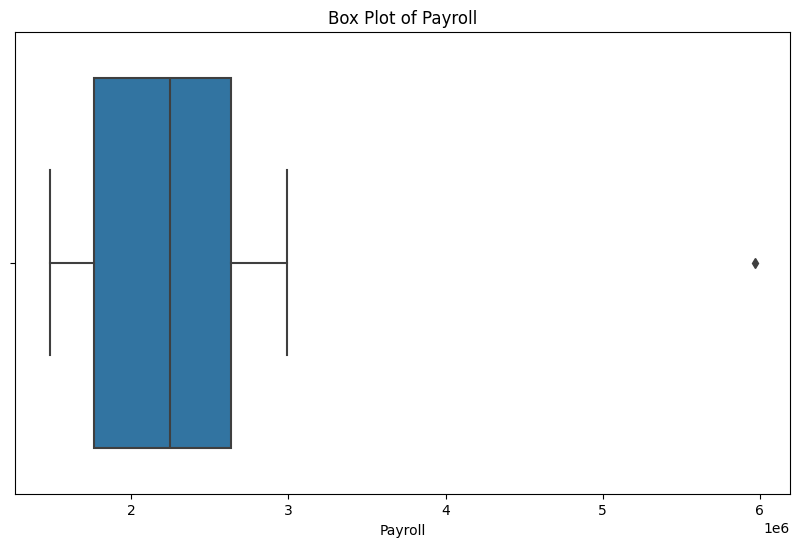

Highest payroll is month 11: 5966451.61


In [6]:
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Payroll'])
plt.title('Box Plot of Payroll')
plt.show()

peak = df.loc[df['Payroll'].idxmax()]
print(f"Highest payroll is month {int(peak['Months_Since_Launch'])}: {peak['Payroll']:.2f}")




Suggested word count: ~50 words



There is one high outlier. In month 11 payroll jumps to about $5.97 million, from about $1.99 million in month 10, then falls back to about $2.21 million in month 12. It is a one-month spike, not a new level. The other months sit in a smoother upward band, which is why the box plot shows a single point above the upper whisker.




## Linear Regression: Payroll (Total 3 marks)

### Step-by-step breakdown:

- (0.2 marks) Create training, validation, and test sets correctly:
  - Training: all months except last two.
  - Validation: second-last month.
  - Test: last month.
  


In [7]:
# Splitting the data
# Training: all months except the last two
train_data = df.iloc[:-2]

# Validation: second-last month
validation_data = df.iloc[[-2]]

# Test: last month
test_data = df.iloc[[-1]]

# Display the sizes of each dataset
print("Training set size:", train_data.shape)
print("Validation set size:", validation_data.shape)
print("Test set size:", test_data.shape)

Training set size: (22, 6)
Validation set size: (1, 6)
Test set size: (1, 6)



  
- (0.5 marks) Train an Ordinary Least Squares (OLS) regressor.



In [8]:
# Preparing training data
X_train = train_data[['Months_Since_Launch']]
y_train = train_data['Payroll']

# Training OLS model
ols_model = LinearRegression()
ols_model.fit(X_train, y_train)

LinearRegression()



- (0.5 marks) Train a robust regressor. Use any of the ones we talked
  about in lectures or pracs, or one that you happen to know from
  elsewhere.



In [9]:
from sklearn.linear_model import HuberRegressor 
robust_model = HuberRegressor()
robust_model.fit(X_train, y_train)

HuberRegressor()



- (0.5 marks) Clearly identify and justify an appropriate evaluation metric.



In [10]:
from sklearn.metrics import mean_absolute_error

X_val = validation_data[['Months_Since_Launch']]
y_val = validation_data['Payroll']

# Metric: mean absolute error, in dollars.
# Payroll is already in dollars, so MAE is the miss in the same units.
# Month 11 is a large spike inside the training window. MAE does not
# square that residual, so the spike does not dominate the score the
# way MSE or RMSE would. With one validation month, MAE is that month's
# absolute error.
print("Evaluation metric: MAE in dollars.")


Evaluation metric: MAE in dollars.




- (0.5 marks) Evaluate both models using the validation set and state which performed better.



In [11]:
# Make predictions using both models on the validation set
ols_val_pred = ols_model.predict(X_val)
robust_val_pred = robust_model.predict(X_val)

# Calculate Mean Absolute Error (MAE) for each model
mae_ols = mean_absolute_error(y_val, ols_val_pred)
mae_robust = mean_absolute_error(y_val, robust_val_pred)

# Print the results
print("OLS Model MAE on Validation Set:", mae_ols)
print("Huber Regressor Model MAE on Validation Set:", mae_robust)

OLS Model MAE on Validation Set: 241220.59194805147
Huber Regressor Model MAE on Validation Set: 96948.53014584398


Huber did better on the validation month. Its MAE is about $96,949, against about $241,221 for OLS.




- (0.3 marks) Report accuracy of the best-performing model on the test set.



In [12]:
X_test = test_data[['Months_Since_Launch']]
y_test = test_data['Payroll']

best_model = robust_model

y_test_pred = best_model.predict(X_test)
ols_test_pred = ols_model.predict(X_test)
test_mae = mean_absolute_error(y_test, y_test_pred)
ols_test_mae = mean_absolute_error(y_test, ols_test_pred)

print("Huber test MAE:", test_mae)
print("OLS test MAE:", ols_test_mae)


Huber test MAE: 10656.121944678482
OLS test MAE: 132196.39018068882




- (0.5 marks) Reflect on and explain why the selected model performed
  better or worse. If it was surprising or expected, explain why.

Suggested word count: ~100 words



Huber was better on the validation month and again on the test month, which is what the month-11 spike would lead me to expect. Validation MAE was about $96,949 for Huber and $241,221 for OLS. Test MAE was about $10,656 for Huber and $132,196 for OLS. Month 11 sits inside the training window at about $5.97 million, against neighbours near $2 million, and least squares is pulled toward that point. Huber switches to a linear penalty once a residual is large, so the line stays with the other months. The size of the error is not stable. The validation miss is about $97,000 and the test miss is about $11,000, so one close test month does not mean a typical miss is $11,000. Leaving month 11 out, Huber's average absolute error on the training months is about $53,000.





### Payroll Prediction (1.5 marks)

- (0.5 marks) Provide your best estimate for payroll in 12 months.



In [13]:
future_months = pd.DataFrame({'Months_Since_Launch': range(25, 37)})  # Months 25 to 36 since launch
future_payroll_preds = robust_model.predict(future_months)

# Print predicted payrolls for each of the next 12 months
predictions = {}
for month, pred in zip(range(25, 37), future_payroll_preds):
    predictions[month] = pred
    print(f"Predicted Payroll for Month {month}: {pred}")

Predicted Payroll for Month 25: 3043193.8359648
Predicted Payroll for Month 26: 3108485.603874278
Predicted Payroll for Month 27: 3173777.3717837557
Predicted Payroll for Month 28: 3239069.1396932337
Predicted Payroll for Month 29: 3304360.9076027116
Predicted Payroll for Month 30: 3369652.67551219
Predicted Payroll for Month 31: 3434944.4434216674
Predicted Payroll for Month 32: 3500236.211331146
Predicted Payroll for Month 33: 3565527.979240624
Predicted Payroll for Month 34: 3630819.7471501017
Predicted Payroll for Month 35: 3696111.5150595796
Predicted Payroll for Month 36: 3761403.2829690576




Suggested word count: ~25 words



The best estimate of payroll in 12 months (month 36) is about $3,761,403. The same Huber line puts the months in between on a steady climb from about $3,043,194 in month 25.




- (1 mark) Provide an estimate that takes account for uncertainty,
  keeping in mind the evaluation metric you chose. If you want to
  calculate additional metrics, you can do that here too.
  


In [14]:
# The test miss (about $10,656) is one month that landed close to the line.
# The half-width used here is the validation MAE of the selected model:
# the out-of-sample absolute error that was used to prefer Huber.
uncertainty_range = mae_robust

point_36 = predictions[36]
print(f"Month 36 payroll: {point_36:.2f}")
print(f"Band is +/- validation MAE ({uncertainty_range:.2f})")
print(f"Month 36 range: [{point_36 - uncertainty_range:.2f}, {point_36 + uncertainty_range:.2f}]")
print()
for month, pred in predictions.items():
    low = pred - uncertainty_range
    high = pred + uncertainty_range
    print(f"Month {month}: Predicted Payroll = {pred:.2f}, Uncertainty Range = [{low:.2f}, {high:.2f}]")


Month 36 payroll: 3761403.28
Band is +/- validation MAE (96948.53)
Month 36 range: [3664454.75, 3858351.81]

Month 25: Predicted Payroll = 3043193.84, Uncertainty Range = [2946245.31, 3140142.37]
Month 26: Predicted Payroll = 3108485.60, Uncertainty Range = [3011537.07, 3205434.13]
Month 27: Predicted Payroll = 3173777.37, Uncertainty Range = [3076828.84, 3270725.90]
Month 28: Predicted Payroll = 3239069.14, Uncertainty Range = [3142120.61, 3336017.67]
Month 29: Predicted Payroll = 3304360.91, Uncertainty Range = [3207412.38, 3401309.44]
Month 30: Predicted Payroll = 3369652.68, Uncertainty Range = [3272704.15, 3466601.21]
Month 31: Predicted Payroll = 3434944.44, Uncertainty Range = [3337995.91, 3531892.97]
Month 32: Predicted Payroll = 3500236.21, Uncertainty Range = [3403287.68, 3597184.74]
Month 33: Predicted Payroll = 3565527.98, Uncertainty Range = [3468579.45, 3662476.51]
Month 34: Predicted Payroll = 3630819.75, Uncertainty Range = [3533871.22, 3727768.28]
Month 35: Predicted P



Suggested word count: ~100 words



The band around each forecast is plus or minus the validation MAE, about $96,949. That is the out-of-sample absolute error of the model that was selected. The test error of about $10,656 is a single close month, so using it as the band would make month 36 look more precise than the validation evidence supports. Month 36 is about $3,761,403, and the band is about $3,664,455 to $3,858,352. This width is a one-month miss. It does not grow just because month 36 is twelve months past the sample, and it would not have contained month 11, which sat about $3.84 million above the same Huber line. A payroll figure can still fall outside the band.




## Revenue Visualisation and Transformation (1 mark)

- (0.5 marks) Visualise revenue over time.



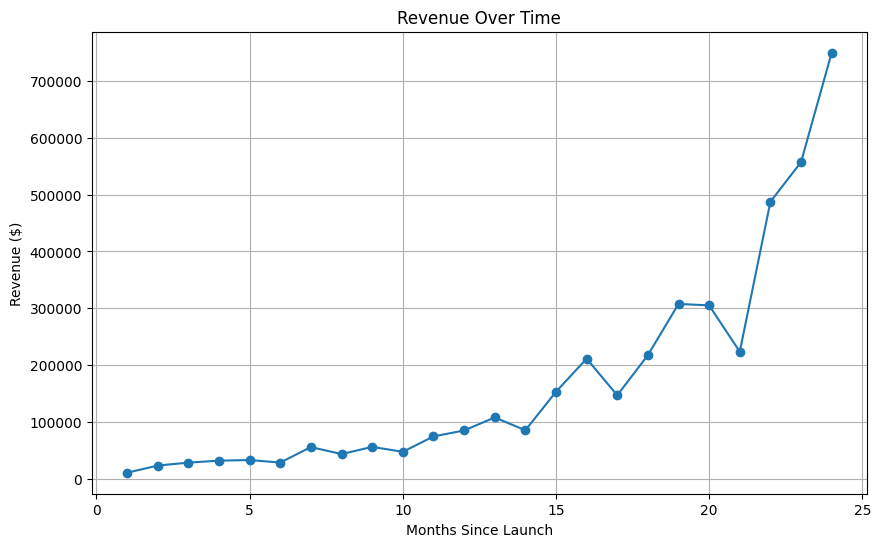

In [15]:
plt.figure(figsize=(10, 6))
plt.plot(df['Months_Since_Launch'], df['Revenue'], marker='o', linestyle='-')
plt.title('Revenue Over Time')
plt.xlabel('Months Since Launch')
plt.ylabel('Revenue ($)')
plt.grid(True)
plt.show()



- (0.5 marks) Clearly explain why applying a log transformation to revenue may help linear modelling.



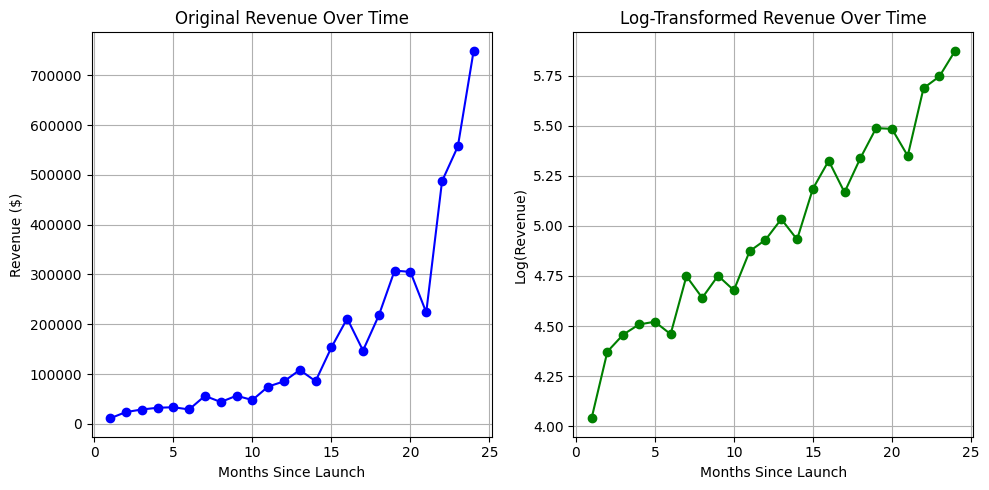

In [16]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(df['Months_Since_Launch'], df['Revenue'], marker='o', linestyle='-', color='blue')
plt.title('Original Revenue Over Time')
plt.xlabel('Months Since Launch')
plt.ylabel('Revenue ($)')
plt.grid(True)

# Plotting Log-Transformed Revenue
plt.subplot(1, 2, 2)
plt.plot(df['Months_Since_Launch'], df['Base_10_Log_Revenue'], marker='o', linestyle='-', color='green')
plt.title('Log-Transformed Revenue Over Time')
plt.xlabel('Months Since Launch')
plt.ylabel('Log(Revenue)')
plt.grid(True)

plt.tight_layout()
plt.show()

Revenue bends upward rather than following a straight line. It starts near $11,000, stays under about $50,000 for much of the first year, and then accelerates to about $749,000 in month 24. A straight line has to split the difference between the flatter early months and the steep later ones. log10 turns a roughly constant percentage increase into an additive step each month, which is the shape linear regression fits. The right-hand plot sits much closer to a straight line than the raw series. The model is fit to log10(revenue), and a forecast has to be converted back with 10 to the power of the prediction so the result is in dollars. A small miss on the log scale becomes a large dollar miss once revenue is high, so a long-range forecast from this fit needs extra caution.




## Revenue Modelling (3 marks)

- (0.5 marks) Train a linear regression model (any model you choose) on the original revenue data.



In [17]:
# Preparing data for original revenue model
X = df[['Months_Since_Launch']]
y = df['Revenue']

# Training the model
original_model = LinearRegression().fit(X, y)



- (0.5 marks) Train a linear regression model on the log-transformed revenue data.



In [18]:
# Preparing data for log-transformed revenue model
y_log = df['Base_10_Log_Revenue']

# Training the model
log_model = LinearRegression().fit(X, y_log)



- (0.5 marks) Compare both models clearly and identify the better-performing model.



In [19]:
from sklearn.metrics import mean_absolute_error, r2_score

y_pred_original = original_model.predict(X)
mae_original = mean_absolute_error(y, y_pred_original)
r2_original = r2_score(y, y_pred_original)

# Score the log model in dollars. MAE on the log10 scale is not comparable
# to MAE in dollars.
y_pred_log_dollars = 10 ** log_model.predict(X)
mae_log_dollars = mean_absolute_error(y, y_pred_log_dollars)
r2_log_dollars = r2_score(y, y_pred_log_dollars)

print(f"Original model - MAE: ${mae_original:,.2f}, R-squared: {r2_original:.2f}")
print(f"Log model, in dollars - MAE: ${mae_log_dollars:,.2f}, R-squared: {r2_log_dollars:.2f}")

better_model = "Log model" if mae_log_dollars < mae_original else "Original model"
print(f"Better fit on the dollar scale: {better_model}")
print("Both scores use the same 24 months the models were fit on.")


Original model - MAE: $78,788.82, R-squared: 0.71
Log model, in dollars - MAE: $30,163.32, R-squared: 0.92
Better fit on the dollar scale: Log model
Both scores use the same 24 months the models were fit on.




Suggested word count: ~25 words



Scored in dollars on the 24 observed months, the log model fits better: MAE about $30,163 and R-squared about 0.92, against about $78,789 and 0.71 for the straight line.




- (0.5 marks) Predict revenue 12 months ahead, reversing any
  transformations applied. Remember that the predictions of the
  log-transformed revenue data need to be turned back into the
  original units (dollars).
  


In [20]:
# Prepare data for prediction (Months 25 to 36)
future_months = pd.DataFrame({'Months_Since_Launch': range(25, 37)})

# Predict log-transformed revenue using the trained log model
log_predictions = log_model.predict(future_months)

# Convert predictions back to original scale (dollars)
predicted_revenue = 10 ** log_predictions  # Reverse log10 transformation

# Display predictions
for month, revenue in zip(range(25, 37), predicted_revenue):
    print(f"Predicted Revenue for Month {month}: ${revenue:.2f}")

Predicted Revenue for Month 25: $666031.74
Predicted Revenue for Month 26: $777547.96
Predicted Revenue for Month 27: $907735.77
Predicted Revenue for Month 28: $1059721.41
Predicted Revenue for Month 29: $1237154.59
Predicted Revenue for Month 30: $1444296.08
Predicted Revenue for Month 31: $1686120.05
Predicted Revenue for Month 32: $1968433.53
Predicted Revenue for Month 33: $2298015.82
Predicted Revenue for Month 34: $2682781.33
Predicted Revenue for Month 35: $3131969.59
Predicted Revenue for Month 36: $3656367.14




Suggested word count: ~25 words



In month 36, twelve months ahead, revenue is about $3.66 million. From month 25 to month 36 the converted log forecast climbs from about $666,000, because the fitted log line is a steady percentage increase.




- (1 mark) Predict revenue 20 years ahead. Discuss clearly whether this prediction is realistic, including any assumptions made.



In [21]:
# Prepare data for prediction (20 years ahead, Month 264)
future_month = pd.DataFrame({'Months_Since_Launch': [264]})

# Predict log-transformed revenue using the trained log model
log_prediction = log_model.predict(future_month)[0]

# Convert prediction back to original scale (dollars)
predicted_revenue = 10 ** log_prediction  # Reverse log10 transformation

# Display prediction
print(f"Predicted Revenue for Month 264 (20 years ahead): ${predicted_revenue:.2f}")

Predicted Revenue for Month 264 (20 years ahead): $7798395831542501867520.00




Suggested word count: ~150 words



Multiple factors make the projected revenue for the next twenty years unrealistic. The model lacks sufficient training data because it only received 24 months of information before attempting to forecast the next 240 months. The linear regression model depends on a steady growth pattern which will not hold true across this extended time span. The logarithmic transformation makes small errors more noticeable when the data returns to its original scale. The model fails to consider various market dynamics alongside economic conditions and business transformations and technological progress which would impact revenue growth. The practical response is to refit the model as new months arrive, and to use the one-year horizon rather than a 20-year extrapolation.





## Logistic Regression: Predicting Negative Media Coverage (3 marks)

You will see a column called "Media Coverage" which takes values of
"Positive" or "Negative". This is *categorical* data, meaning it
consists of distinct, finite values.

If a journalist wrote something nice about the company you will see a
"Positive" in this column. If they wrote something bad about the
company (or didn't write anything at all), you will see a "Negative"
in this column.

- (0.5 marks) Which features will you use to predict "Media Coverage"?

Suggested word count: ~50 words



I use Months_Since_Launch, Payroll, Revenue, and Scandals. Coverage flips from Positive to Negative at month 11 and stays Negative, so the month number is the clearest signal. Payroll and revenue are the figures the other models can forecast for that future month. Scandals stays in because the month-36 case sets it to zero. I leave out Base_10_Log_Revenue, which repeats Revenue, and I standardise the four columns so the coefficients can be compared.




- (0.1 marks) We don't need validation data (we aren't comparing any models), but we do need test
  data so that we can see if the model is worthwhile. Randomly select some data to act as test
  data.
  


In [22]:
# Month tracks the Positive-to-Negative break after month 10.
# Payroll and Revenue are the operating figures forecast above.
# Scandals is included so the month-36 case can set it to zero.
# Base_10_Log_Revenue is omitted because it repeats Revenue.
media_features = ['Months_Since_Launch', 'Payroll', 'Revenue', 'Scandals']
X_media = df[media_features]
y_media = (df['Media Coverage'] == 'Negative').astype(int)

X_train_media, X_test_media, y_train_media, y_test_media = train_test_split(
    X_media, y_media, test_size=0.2, random_state=42
)



  
- (0.1 marks) Train a logistic regression model on the training (non-test) data



In [23]:
scaler = StandardScaler()
X_train_media_s = scaler.fit_transform(X_train_media)
X_test_media_s = scaler.transform(X_test_media)

logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_train_media_s, y_train_media)


LogisticRegression(max_iter=1000, random_state=42)



- (0.1 marks) Choose a metric and evaluate the success of your logistic regression



In [24]:
y_pred = logistic_model.predict(X_test_media_s)
accuracy = accuracy_score(y_test_media, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print(f"Test rows: {len(y_test_media)}")

conf_matrix = confusion_matrix(y_test_media, y_pred)
print("Confusion matrix (rows actual, columns predicted; 0 = Positive, 1 = Negative):")
print(conf_matrix)


Accuracy: 1.00
Test rows: 5
Confusion matrix (rows actual, columns predicted; 0 = Positive, 1 = Negative):
[[2 0]
 [0 3]]




- (0.1 marks) Examine the coefficients of the logistic regression model that you created.



In [25]:
coefficients = pd.DataFrame({
    'Feature': X_train_media.columns,
    'Coefficient': logistic_model.coef_[0]
}).sort_values('Coefficient', ascending=False)

print(coefficients.to_string(index=False))
print("Coefficients are for standardised features, so a larger value means a stronger association per standard deviation.")


            Feature  Coefficient
Months_Since_Launch     1.426391
            Payroll     0.866892
            Revenue     0.740214
           Scandals     0.403510


Coefficients are for standardised features, so a larger value means a stronger association per standard deviation.




- (1 mark) Clearly discuss the logistic regression coefficients and
  identify the most influential features contributing to negative
  media coverage.
  
  Suggested word count: ~150 words



The coefficients are on standardised features, so they can be compared with each other. Months_Since_Launch is the strongest, at about 1.43: a later month raises the log-odds of negative coverage by more than a one-standard-deviation move in any other column. Payroll (about 0.87) and Revenue (about 0.74) are also positive, so a larger wage bill or higher revenue lines up with a higher chance of negative coverage in this file. They are not separate causes. Both series rise over the same months in which coverage turns negative, so they share the time trend. Scandals is the weakest, at about 0.40. It is 0 in 23 of 24 months and equals 1 only in month 14, which was already inside the negative run, so the fit has almost nothing to learn from it. Comparing raw coefficients would have been misleading, because payroll and revenue are in dollars and a dollar is a tiny step next to a 0/1 scandal flag. With 24 months and only one scandal, none of these coefficients is a stable measure of cause.




- (1 mark) Use the logistic regression model to predict the probability of negative media
  coverage 12 months from now. Assume that there are no scandals in that month.
  


In [26]:
future_month = 36
future_payroll = float(robust_model.predict(pd.DataFrame({'Months_Since_Launch': [future_month]}))[0])
future_revenue = float(10 ** log_model.predict(pd.DataFrame({'Months_Since_Launch': [future_month]}))[0])

future_data = pd.DataFrame({
    'Months_Since_Launch': [future_month],
    'Payroll': [future_payroll],
    'Revenue': [future_revenue],
    'Scandals': [0]
})

probability = float(logistic_model.predict_proba(scaler.transform(future_data))[0, 1])
print(future_data.to_string(index=False))
print(f"Predicted probability of negative media coverage in month 36: {probability:.6f}")


 Months_Since_Launch      Payroll      Revenue  Scandals
                  36 3.761403e+06 3.656367e+06         0
Predicted probability of negative media coverage in month 36: 1.000000




Suggested word count: ~25 words



With month 36, the forecast payroll, the forecast revenue, and no scandal, the model returns a probability of negative coverage of about 1.00. That is not a calibrated certainty. Coverage has been negative in every month since month 10, so the logistic curve is already saturated by month 36. The fair conclusion is that negative coverage is the likely continuation, not that it is guaranteed.




- (0.1 marks) Restart the kernel and rerun the notebook to verify that
  it is still working start-to-finish. Enter the "RESTARTED AND
  CHECKED" in the next cell when you have done this.
  
  Suggested word count: 3 words
  


RESTARTED AND CHECKED




## Written Summary of Findings (1.5 marks)

- Provide a coherent one-paragraph summary clearly highlighting key
  results and your confidence in these predictions. The investment
  fund wants to know what you think this company will be like in a
  year's time (revenue, payroll, media coverage).
  
Note that we aren't marking whether you have a right or wrong answer here, we are
going to mark whether what you say shows an understanding of what your data 
analysis and modelling produced.

If you want to add any visualisations here, you can.





Suggested word count: ~250 words



Twelve months on from month 24, payroll and revenue are both higher, and media coverage is still negative if the last fourteen months continue. I would trust the payroll level more than the revenue level. Huber puts month-36 payroll at about $3,761,403, up from $2,988,558 in month 24. It was the better model on the validation month, with an absolute error of about $96,949 against about $241,221 for least squares, and again on the test month, about $10,656 against $132,196. The least-squares line is pulled by the month-11 spike of about $5.97 million. The band I would quote is plus or minus that validation error, about $3.66 million to $3.86 million. It is only a one-month miss: it does not widen at a twelve-month horizon, and it would not have contained month 11, which sat about $3.84 million above the Huber line. Revenue in month 36 is about $3,656,367 after the log10 fit is turned back into dollars, up from about $749,421 in month 24. On the observed months that fit beats a straight line when both are scored in dollars, with MAE about $30,163 and R-squared about 0.92 against about $78,789 and 0.71. It still assumes the recent percentage growth lasts another year, and the same line at twenty years is meaningless, so the one-year revenue figure is a growth-rate projection rather than a reliable level. Coverage was Positive in months 1 to 10 and Negative from month 11 on. With month 36, the two forecasts, and no scandal, the logistic model returns a probability indistinguishable from 1. I would expect negative coverage to continue, and I would not defend that 1 as a real probability: 24 rows and one clean break in the labels make the model saturate.





## 2-Minute Video Presentation (1.5 marks)

Some of your (non-technical) colleagues in this venture capital firm
are in other timezones, and don't know how to program, so you need to
create a video presentation for them describing your insights.

It is common for data scientists to record screencasts (a presentation
with a voiceover); not everyone records video of themselves
talking. Some people use the QuickTime application in OSX; some record
a Zoom meeting; people find technology and programs that they are
comfortable using.

Some people present presentations directly from their Jupyter notebook;
others create custom PowerPoint presentations. 

So your choices in this section are quite open. 

- (0.5 marks) Submit a video, and ensure the video is in low resolution (SD, 480p)
  so that it is small enough to upload. Keep the time to around 2
  minutes.

- (0.6 marks) State what you believe will happen to this startup over the next 12 months:
  revenue, payroll, positive/negative media coverage. (0.6 marks)
  
- (0.4 marks) Briefly discuss any limitations or assumptions you made
  in your analysis and how they might affect your predictions. Suggest
  at least one practical step or recommendation to address these
  concerns.






## Late Assessment Submission Penalty 

Unless a Special Consideration request has been submitted and
approved, a 5% penalty (of the total possible mark of the task) will
be applied for each day a written report or presentation assessment is
not submitted, up until the 7th day (including weekends). After the
7th day, a grade of ‘0’ will be awarded even if the assessment is
submitted. The submission time for all uploaded assessments is 11:55
pm. A 1-hour grace period will be provided to students who experience
a technical concern. For any late submission of time-sensitive tasks,
such as scheduled tests/exams, performance assessments/presentations,
and/or scheduled practical assessments/labs, please apply for
[Special Consideration](https://students.mq.edu.au/study/assessment-exams/special-consideration).

For example, as this assignment is worth 15% of the entire unit, a
submission late by up to 24 hours will incur a penalty of 0.75 marks
(5% of 15 marks). A submission that is late by between 24 and 48 hours
will incur a penalty of 1.5 marks (10% of 15 marks), and so on.

## Sample Gen-AI prompts

Programming prompts:

```
Don't give me the answer directly, but help guide me to answering
this question. I will be programming in Python using the pandas and scikit-learn
libraries. If it appears that I don't know something that I would need to 
answer a question, suggest functions or classes that I should learn about. Always
add little bits of information that will guide my journey.

Here is my code so far, and the question I am trying to answer
(....)
```

If you are concerned about your grammar or language, try a prompt like this:

```
Find any grammatical mistakes, typos or other language errors in this
text. Don't make the corrections, just list for me what was wrong and
explain the problem.
```

